In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

Selecting previously unselected package fonts-nanum.
(Reading database ... 126102 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...


In [15]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
import pandas as pd

In [4]:
# 'air_2021.csv'파일을 'air_21' 변수에, 'air_2022.csv'파일을 'air_22' 변수에 저장
df_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/11주차/df_21_v2.csv', index_col='time', parse_dates=True)
df_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/11주차/df_22_v2.csv', index_col='time', parse_dates=True)

In [5]:
df_21.head(3)

,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),풍향(16방위),...,중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),PM_lag1,PM10_1
time,,,,,,,,,,,,,,,,,,,,,
2021-01-01 01:00:00,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,2.4,270.0,...,0,0.0,2000,-6.9,-1.0,-0.8,0.3,1.6,11.0,25.0
2021-01-01 02:00:00,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,1.6,270.0,...,0,0.0,2000,-7.1,-1.1,-0.8,0.3,1.6,27.0,27.0
2021-01-01 03:00:00,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,1.1,250.0,...,0,0.0,2000,-7.3,-1.2,-0.9,0.3,1.6,17.0,23.0


In [6]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
# 다변량 시계열 데이터셋 준비
X_train = df_21[['PM10', 'PM_lag1']]
y_train = df_21['PM10_1']
X_test = df_22[['PM10', 'PM_lag1']]
y_test = df_22['PM10_1']

# 모델 학습
model_arimax = SARIMAX(y_train, exog=X_train, order=(1, 0, 0), enforce_stationarity=False, enforce_invertibility=False)
result_arimax = model_arimax.fit()


pred_arimax = result_arimax.predict(start=len(y_train), end=len(y_train) + len(y_test) - 1, exog=X_test)

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


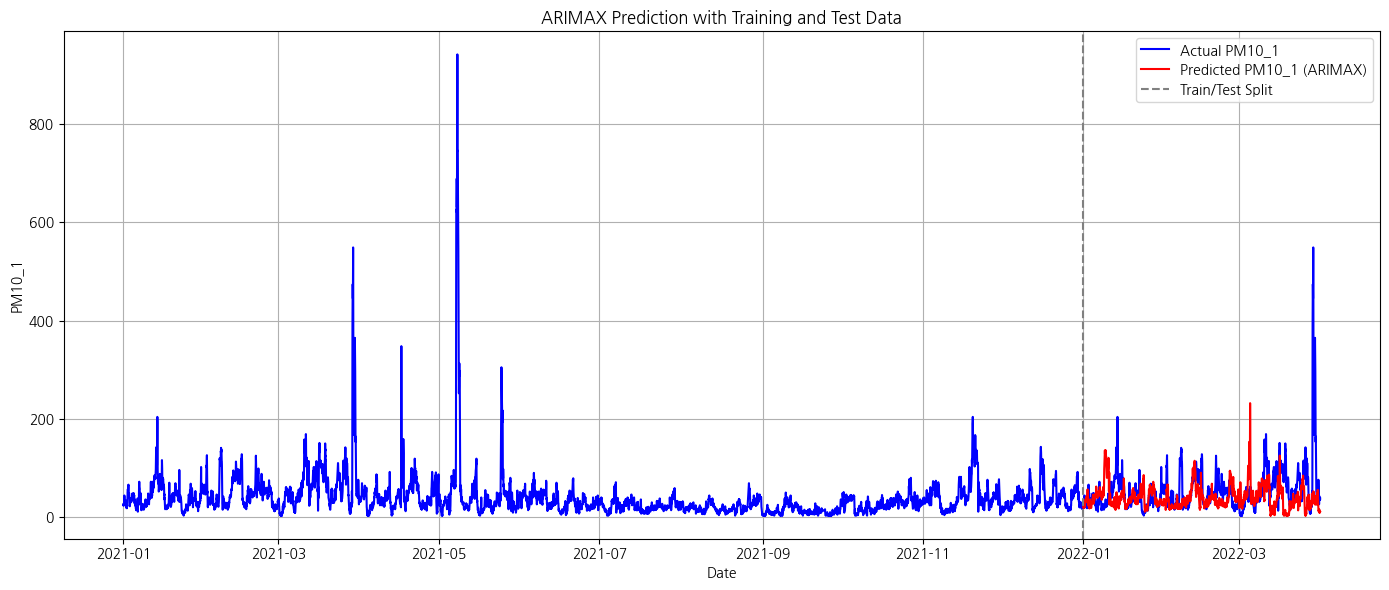

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

# 예측 결과 시리즈화 (인덱스 맞추기)
pred_arimax = pd.Series(pred_arimax, index=y_test.index)

# 실제 관측값 연결 (train + test)
y_all = pd.concat([y_train, y_test])

# 예측값을 전체 구간에 맞게 확장 (train 구간은 NaN으로 채움)
pred_full = pd.Series([None]*len(y_train), index=y_train.index)
pred_full = pd.concat([pred_full, pred_arimax])

# 시각화
plt.figure(figsize=(14, 6))
plt.plot(y_all, label='Actual PM10_1', color='blue')
plt.plot(pred_full, label='Predicted PM10_1 (ARIMAX)', color='red')
plt.axvline(x=y_test.index[0], color='gray', linestyle='--', label='Train/Test Split')
plt.title('ARIMAX Prediction with Training and Test Data')
plt.xlabel('Date')
plt.ylabel('PM10_1')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

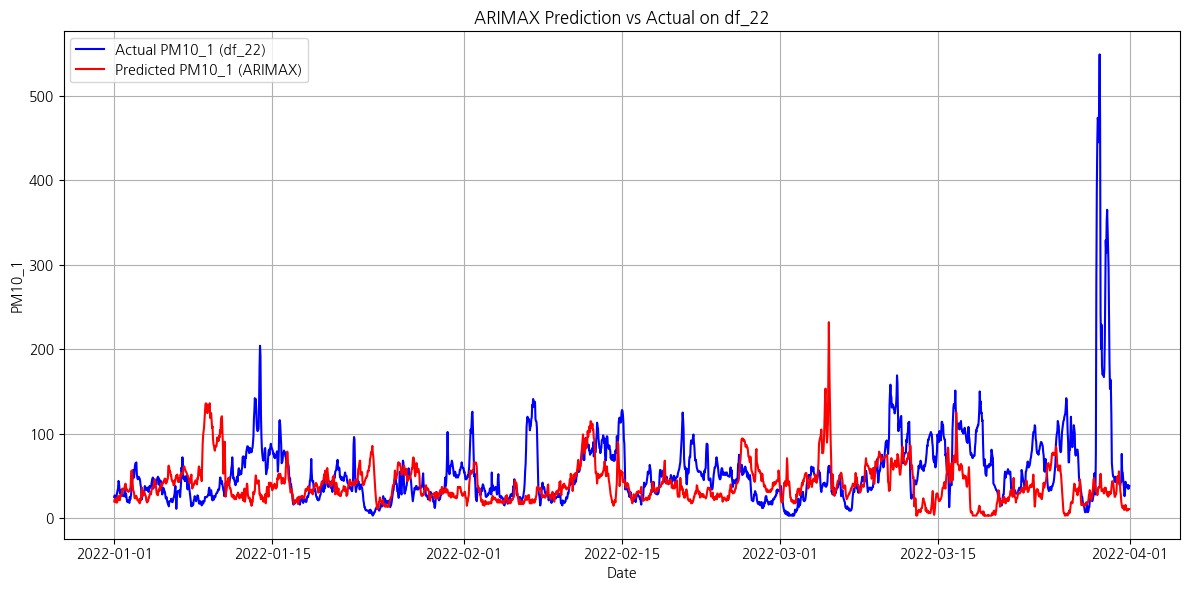

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

# 예측값 인덱스를 y_test에 맞춤
pred_arimax = pd.Series(pred_arimax, index=y_test.index)

# 시각화
plt.figure(figsize=(12, 6))
plt.plot(y_test, label='Actual PM10_1 (df_22)', color='blue')
plt.plot(pred_arimax, label='Predicted PM10_1 (ARIMAX)', color='red')
plt.title('ARIMAX Prediction vs Actual on df_22')
plt.xlabel('Date')
plt.ylabel('PM10_1')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


<ipython-input-18-4f673d026447>:14: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill')
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.0019 - val_loss: 1.3343e-04
Epoch 2/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 4.8410e-04 - val_loss: 1.0076e-04
Epoch 3/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 3.8627e-04 - val_loss: 8.0899e-05
Epoch 4/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2.6163e-04 - val_loss: 7.5471e-05
Epoch 5/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 2.2179e-04 - val_loss: 6.2537e-05
Epoch 6/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 2.0749e-04 - val_loss: 5.7197e-05
Epoch 7/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 2.4827e-04 - val_loss: 5.3957e-05
Epoch 8/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1.8591e-04 - val_loss: 4.5629e-05
Epoch 9/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 1.4695e-04 - val_loss: 4.7730e-05
Epoch 10/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 1.6904e-04 - val_loss: 6.4031e-05
Epoch 11/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step

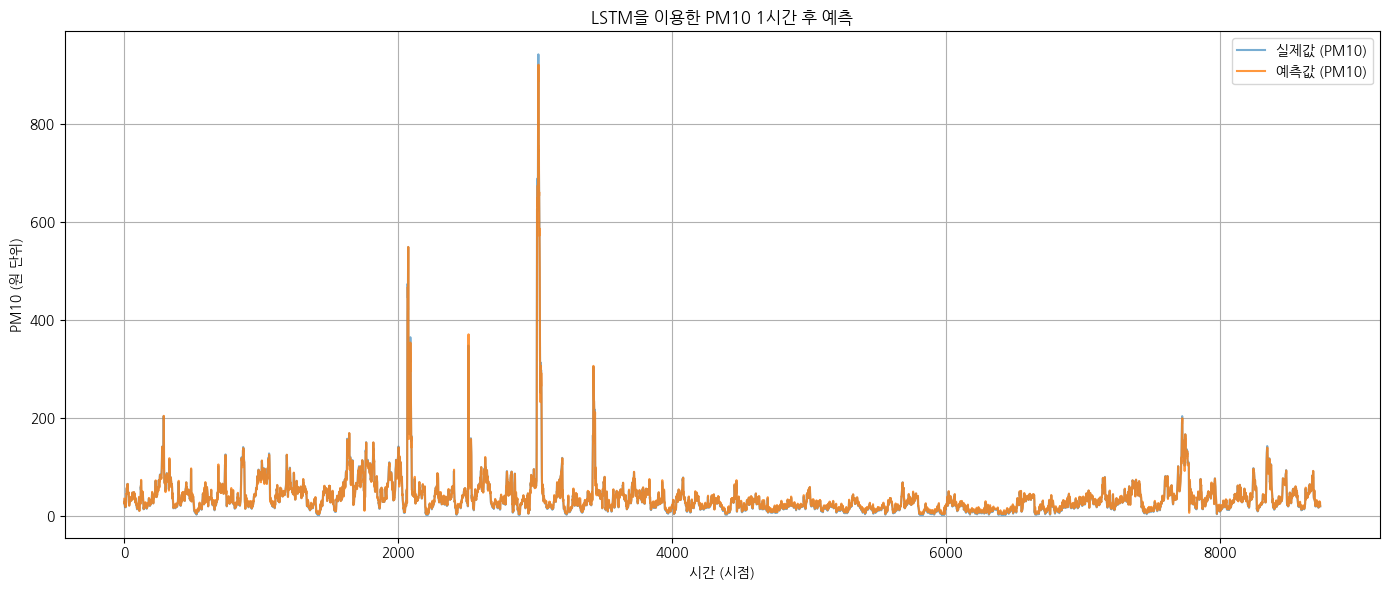

In [18]:
# 필요한 라이브러리
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# --- 1. 데이터 불러오기 및 전처리 ---
# CSV 파일은 'datetime'과 'PM10' 컬럼이 있다고 가정합니다.
df = df_21.copy()  # 경로를 본인의 파일로 바꾸세요

# 결측값 처리
df = df.fillna(method='ffill')

# 정규화
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df[['PM10']])

# --- 2. 시계열 샘플 생성 함수 ---
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

window_size = 24  # 과거 24시간을 사용
X, y = create_sequences(scaled_data, window_size)

# LSTM 입력 형태로 변형: (samples, timesteps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))

# --- 3. 모델 정의 및 학습 ---
model = Sequential()
model.add(LSTM(64, activation='relu', input_shape=(window_size, 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')

# 학습
model.fit(X, y, epochs=20, batch_size=32, validation_split=0.1)

# --- 4. 예측 및 복원 ---
y_pred = model.predict(X)
y_pred_inv = scaler.inverse_transform(y_pred)
y_true_inv = scaler.inverse_transform(y)

# --- 5. 시각화 ---
plt.figure(figsize=(14,6))
plt.plot(y_true_inv, label='실제값 (PM10)', alpha=0.6)
plt.plot(y_pred_inv, label='예측값 (PM10)', alpha=0.8)
plt.title('LSTM을 이용한 PM10 1시간 후 예측')
plt.xlabel('시간 (시점)')
plt.ylabel('PM10 (원 단위)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


245/245 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0024 - val_loss: 5.0385e-04
Epoch 2/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0016 - val_loss: 5.4231e-04
Epoch 3/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0021 - val_loss: 5.2021e-04
Epoch 4/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.0017 - val_loss: 4.7065e-04
Epoch 5/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.0015 - val_loss: 4.8533e-04
Epoch 6/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0015 - val_loss: 5.7955e-04
Epoch 7/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.0018 - val_loss: 4.7282e-04
Epoch 8/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0014 - val_loss: 5.7516e-04
Epoch 9/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0017 - val_loss: 4.8640e-04
Epoch 10/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0013 - val_loss: 6.5111e-04
Epoch 11/20
245/245 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0016 - val_loss: 4.9159e-04
Epoch 12

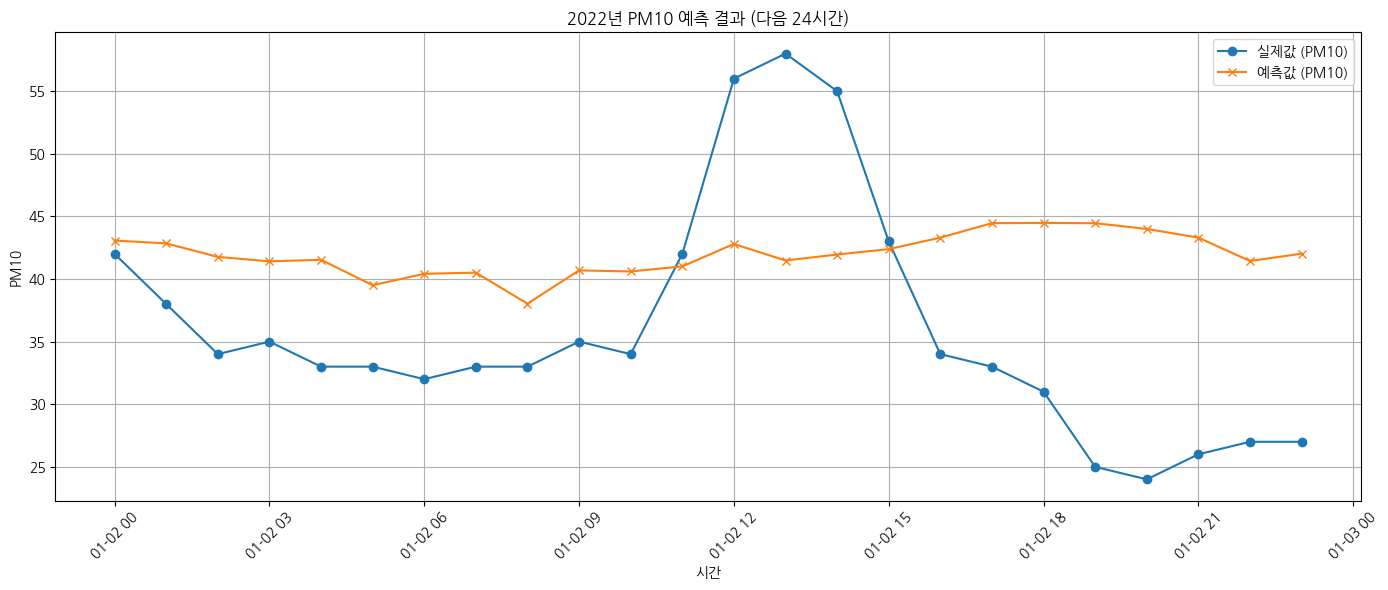

In [26]:
# 라이브러리
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# --- 1. 데이터 불러오기 ---
df_21 = df_21.copy()   # 학습용
df_22 = df_22.copy()   # 예측용



# 3. 정규화
scaler = MinMaxScaler()
scaled_21 = scaler.fit_transform(df_21[['PM10']])
scaled_22 = scaler.transform(df_22[['PM10']])

# 4. 시퀀스 생성 함수 (다중 출력)
def create_multistep_sequences(data, input_steps, output_steps):
    X, y = [], []
    for i in range(len(data) - input_steps - output_steps + 1):
        X.append(data[i:i + input_steps])
        y.append(data[i + input_steps : i + input_steps + output_steps])
    return np.array(X), np.array(y)

input_steps = 24   # 입력: 과거 24시간
output_steps = 24  # 출력: 미래 24시간

# 학습 데이터 생성
X_train, y_train = create_multistep_sequences(scaled_21, input_steps, output_steps)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))

# 5. 모델 정의 및 학습
model = Sequential()
model.add(LSTM(64, activation='relu', input_shape=(input_steps, 1)))
model.add(Dense(output_steps))
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.1)

# 6. 테스트 데이터 생성
X_test, y_test = create_multistep_sequences(scaled_22, input_steps, output_steps)
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# 7. 예측 및 역정규화
y_pred_scaled = model.predict(X_test)

y_pred = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(y_pred_scaled.shape[0], y_pred_scaled.shape[1])
y_true = scaler.inverse_transform(y_test.reshape(-1, 1)).reshape(y_test.shape[0], y_test.shape[1])

# 8. datetime 축 생성
# 예측 시작 시점들
start_times = df_22.index[input_steps : input_steps + len(y_true)]

# 첫 샘플 기준, 24시간 후 시점 생성
first_pred_time = start_times[0]
time_range = [first_pred_time + pd.Timedelta(hours=i) for i in range(output_steps)]

# 9. 시각화 (datetime 축)
plt.figure(figsize=(14,6))
plt.plot(time_range, y_true[0], label='실제값 (PM10)', marker='o')
plt.plot(time_range, y_pred[0], label='예측값 (PM10)', marker='x')
plt.title('2022년 PM10 예측 결과 (다음 24시간)')
plt.xlabel('시간')
plt.ylabel('PM10')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [24]:
y_test.shape

(2113, 24, 1)